# Evaluare 01: Învățarea supervizată
**Student:** Trandafir Florin-Daniel

Acest test evaluează importul și vizualizarea datelor, metricile și modelele de învățare supervizată.

## 1. Importul datelor
1. Importă biblioteca `pandas` și încarcă fișierul `Human_Activity_Recognition_Using_Smartphones_Data.csv`.
2. Verifică dimensiunile și tipurile de date.
3. Afișează primele 5 rânduri din DataFrame și verifică prezența valorilor lipsă.

In [1]:
# Punctul 1.1 — importăm bibliotecile necesare și pregătim încărcarea datelor.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

RANDOM_STATE = 42
csv_files = sorted(Path('.').glob('Human_Activity_Recognition_Using_Smartphones_Data*.csv'))
if not csv_files:
    raise FileNotFoundError('Fișierul CSV nu a fost găsit.')

# Punctul 1.1 — încărcăm fișierul CSV în DataFrame-ul df.
df = pd.read_csv(csv_files[0])
print(f'Fișier: {csv_files[0].name}')
# Punctul 1.2 — verificăm dimensiunile setului de date și tipurile coloanelor.
print(f'Dimensiuni: {df.shape[0]} rânduri × {df.shape[1]} coloane')
print('Tipuri de date:')
display(df.dtypes.value_counts().rename('număr coloane').to_frame())
# Punctul 1.3 — afișăm primele 5 rânduri și verificăm valorile lipsă.
display(df.head())
print(f'Valori lipsă: {int(df.isna().sum().sum())}')

Fișier: Human_Activity_Recognition_Using_Smartphones_Data.csv
Dimensiuni: 10299 rânduri × 562 coloane
Tipuri de date:


,număr coloane
float64,561
str,1


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,STANDING


Valori lipsă: 0


## 2. Vizualizare date cu Matplotlib și Seaborn
1. Creează un grafic scatter care să afișeze relația dintre două coloane numerice.
2. Utilizează Seaborn pentru a crea o hartă de căldură (heatmap) a corelațiilor dintre coloane.

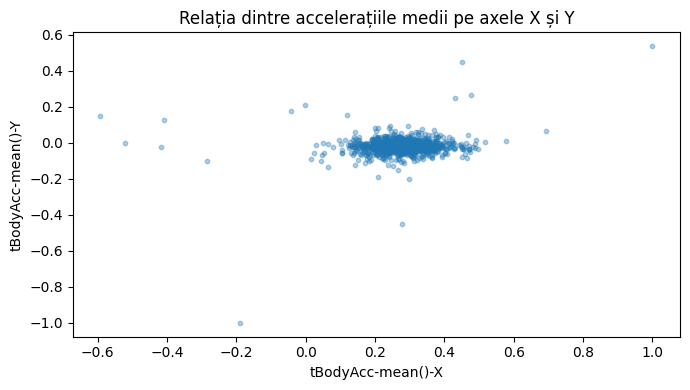

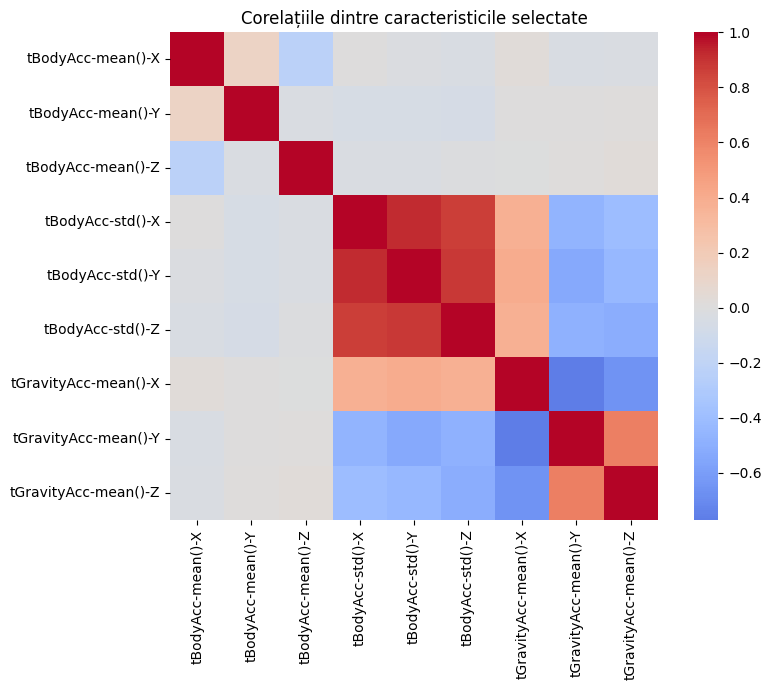

Concluzie: graficele evidențiază relațiile și corelațiile dintre semnalele selectate.


In [2]:
# Punctul 2.1 — construim graficul scatter pentru două coloane numerice.
sample = df.sample(n=min(2000, len(df)), random_state=RANDOM_STATE)
plt.figure(figsize=(7, 4))
plt.scatter(sample['tBodyAcc-mean()-X'], sample['tBodyAcc-mean()-Y'], s=10, alpha=0.35)
plt.xlabel('tBodyAcc-mean()-X')
plt.ylabel('tBodyAcc-mean()-Y')
plt.title('Relația dintre accelerațiile medii pe axele X și Y')
plt.tight_layout()
plt.show()

# Punctul 2.2 — calculăm corelațiile și le reprezentăm printr-un heatmap Seaborn.
heatmap_columns = [
    'tBodyAcc-mean()-X', 'tBodyAcc-mean()-Y', 'tBodyAcc-mean()-Z',
    'tBodyAcc-std()-X', 'tBodyAcc-std()-Y', 'tBodyAcc-std()-Z',
    'tGravityAcc-mean()-X', 'tGravityAcc-mean()-Y', 'tGravityAcc-mean()-Z'
]
plt.figure(figsize=(9, 7))
sns.heatmap(df[heatmap_columns].corr(), cmap='coolwarm', center=0, square=True)
plt.title('Corelațiile dintre caracteristicile selectate')
plt.tight_layout()
plt.show()
print('Concluzie: graficele evidențiază relațiile și corelațiile dintre semnalele selectate.')

## 3. Metrici ale erorii
1. Împarte setul de date în seturi de antrenare și testare (80%-20%).
2. Construiește un model de regresie liniară pe datele numerice.
3. Evaluează performanța modelului utilizând **MAE**, **MSE** și **RMSE**.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Punctul 3.1 — alegem variabilele și împărțim datele în 80% antrenare / 20% testare.
regression_target = 'tBodyAcc-mean()-X'
numeric_data = df.select_dtypes(include='number')
X_reg = numeric_data.drop(columns=regression_target)
y_reg = numeric_data[regression_target]
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=RANDOM_STATE
)
# Punctul 3.2 — construim și antrenăm modelul de regresie liniară.
linear_model = LinearRegression(n_jobs=-1)
linear_model.fit(X_train_reg, y_train_reg)
y_pred_reg = linear_model.predict(X_test_reg)

# Punctul 3.3 — evaluăm modelul folosind MAE, MSE și RMSE (plus R²).
mae = mean_absolute_error(y_test_reg, y_pred_reg)
mse = mean_squared_error(y_test_reg, y_pred_reg)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_reg, y_pred_reg)
print(f'MAE:  {mae:.6f}')
print(f'MSE:  {mse:.6f}')
print(f'RMSE: {rmse:.6f}')
print(f'R²:   {r2:.6f}')
print(f'Concluzie: modelul explică {r2:.2%} din variația țintei numerice.')

MAE:  0.023176
MSE:  0.001547
RMSE: 0.039331
R²:   0.688032
Concluzie: modelul explică 68.80% din variația țintei numerice.


## 4. Validare încrucișată (Cross Validation)
1. Importă biblioteca `scikit-learn`.
2. Împarte setul de date în seturi de antrenare și testare (80%-20%).
3. Utilizează `cross_val_score` pentru a evalua performanța unui model KNN pe setul de date.

In [4]:
# Punctul 4.1 — importăm scikit-learn și componentele necesare.
import sklearn
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# Punctul 4.2 — împărțim datele de clasificare în 80% antrenare / 20% testare.
X_cls = df.drop(columns='Activity')
y_cls = df['Activity']
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls, y_cls, test_size=0.20, random_state=RANDOM_STATE, stratify=y_cls
)
# Punctul 4.3 — evaluăm modelul KNN prin validare încrucișată cu 5 partiții.
knn_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn_scores = cross_val_score(
    knn_model, X_train_cls, y_train_cls, cv=5, scoring='accuracy', n_jobs=-1
)
print(f'scikit-learn: {sklearn.__version__}')
print(f'Acurateți KNN: {np.round(knn_scores, 4)}')
print(f'Medie: {knn_scores.mean():.4f} ± {knn_scores.std():.4f}')
print('Concluzie: scorurile apropiate indică o performanță stabilă între partiții.')

scikit-learn: 1.9.1
Acurateți KNN: [0.9551 0.9563 0.9521 0.9593 0.9514]
Medie: 0.9548 ± 0.0029
Concluzie: scorurile apropiate indică o performanță stabilă între partiții.


## 5. Modele de Machine Learning
1. **Regresia liniară**: antrenează un model de regresie liniară și evaluează performanța acestuia pe setul de testare.
2. **Regresia logistică**: construiește un model logistic pentru o problemă de clasificare binară.
3. **SVM**: antrenează un model SVM și testează-l pe setul de date.

In [5]:
# Punctul 5 — importăm modelele și metrica necesare comparației.
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Pregătim aceeași problemă binară și aceeași împărțire pentru punctele 5.2 și 5.3.
y_binary = (df['Activity'] == 'WALKING').astype(int)
X_train_bin, X_test_bin, y_train_bin, y_test_bin = train_test_split(
    X_cls, y_binary, test_size=0.20, random_state=RANDOM_STATE, stratify=y_binary
)
# Punctul 5.1 — raportăm performanța regresiei liniare antrenate la punctul 3.
print(f'Regresie liniară — RMSE: {rmse:.6f}, R²: {r2:.6f}')

Regresie liniară — RMSE: 0.039331, R²: 0.688032


In [6]:
# Punctul 5.2 — construim, antrenăm și evaluăm modelul de regresie logistică binară.
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
)
logistic_model.fit(X_train_bin, y_train_bin)
y_pred_logistic = logistic_model.predict(X_test_bin)
logistic_accuracy = accuracy_score(y_test_bin, y_pred_logistic)
print(f'Acuratețe Logistic Regression: {logistic_accuracy:.4f}')

Acuratețe Logistic Regression: 0.9995


In [7]:
# Punctul 5.3 — construim, antrenăm și evaluăm modelul SVM.
svm_model = make_pipeline(StandardScaler(), SVC(kernel='rbf', random_state=RANDOM_STATE))
svm_model.fit(X_train_bin, y_train_bin)
y_pred_svm = svm_model.predict(X_test_bin)
svm_accuracy = accuracy_score(y_test_bin, y_pred_svm)
print(f'Acuratețe SVM: {svm_accuracy:.4f}')
print(f'Concluzie: modelul cu acuratețea mai mare este {"SVM" if svm_accuracy > logistic_accuracy else "Logistic Regression" if logistic_accuracy > svm_accuracy else "egalitate"}.')

Acuratețe SVM: 0.9995
Concluzie: modelul cu acuratețea mai mare este egalitate.


## 6. Matricea de confuzie
1. Construiește un model de clasificare logistică.
2. Creează matricea de confuzie și afișeaz-o grafic utilizând Seaborn.

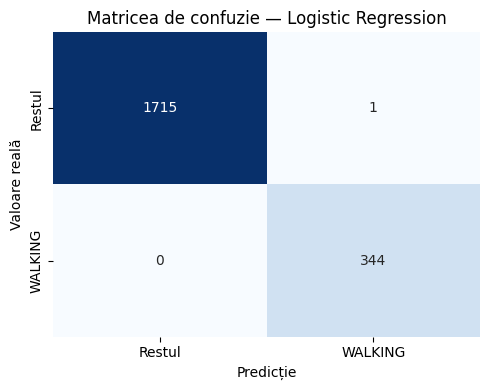

Clasificări corecte: 2059 din 2060.


In [8]:
# Punctul 6.1 — reutilizăm modelul logistic antrenat la punctul 5.2.
from sklearn.metrics import confusion_matrix

# Punctul 6.2 — calculăm matricea de confuzie și o afișăm grafic cu Seaborn.
cm = confusion_matrix(y_test_bin, y_pred_logistic)
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', cbar=False,
    xticklabels=['Restul', 'WALKING'], yticklabels=['Restul', 'WALKING']
)
plt.xlabel('Predicție')
plt.ylabel('Valoare reală')
plt.title('Matricea de confuzie — Logistic Regression')
plt.tight_layout()
plt.show()
print(f'Clasificări corecte: {int(np.trace(cm))} din {int(cm.sum())}.')

## 7. Gradient Descent
1. Implementează manual algoritmul Gradient Descent pentru a optimiza o funcție cost definită.
2. Utilizează funcția $J(\theta)=\mathrm{mean}((\theta x-y)^2)$ pe un subset al datelor.

θ optim: 0.163690
Cost inițial: 1.000000
Cost final:   0.973205


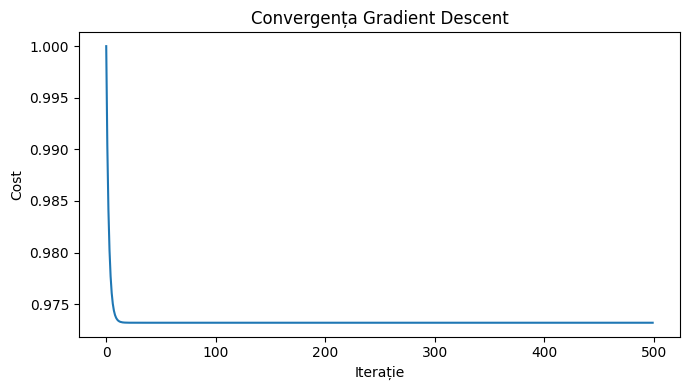

Concluzie: costul scade și algoritmul converge.


In [9]:
# Punctul 7.2 — selectăm și standardizăm subsetul folosit în funcția de cost.
x_gd = df['tBodyAcc-mean()-Y'].to_numpy()[:1000]
y_gd = df['tBodyAcc-mean()-X'].to_numpy()[:1000]
x_gd = (x_gd - x_gd.mean()) / x_gd.std()
y_gd = (y_gd - y_gd.mean()) / y_gd.std()

# Punctul 7.1 — implementăm manual Gradient Descent pentru optimizarea parametrului theta.
theta = 0.0
learning_rate = 0.1
cost_history = []
for _ in range(500):
    error = theta * x_gd - y_gd
    # Punctul 7.2 — calculăm J(theta) = mean((theta * x - y)²).
    cost_history.append(np.mean(error ** 2))
    theta -= learning_rate * 2 * np.mean(error * x_gd)

print(f'θ optim: {theta:.6f}')
print(f'Cost inițial: {cost_history[0]:.6f}')
print(f'Cost final:   {cost_history[-1]:.6f}')
plt.figure(figsize=(7, 4))
plt.plot(cost_history)
plt.xlabel('Iterație')
plt.ylabel('Cost')
plt.title('Convergența Gradient Descent')
plt.tight_layout()
plt.show()
print('Concluzie: costul scade și algoritmul converge.')

## 8. Modele de Machine Learning (partea 2 — opțional)
1. **Random Forest**: utilizează Random Forest pentru a antrena un model și evaluează importanța caracteristicilor.
2. **Boosting și Bagging**: compară performanța dintre un model AdaBoost și un model Bagging.

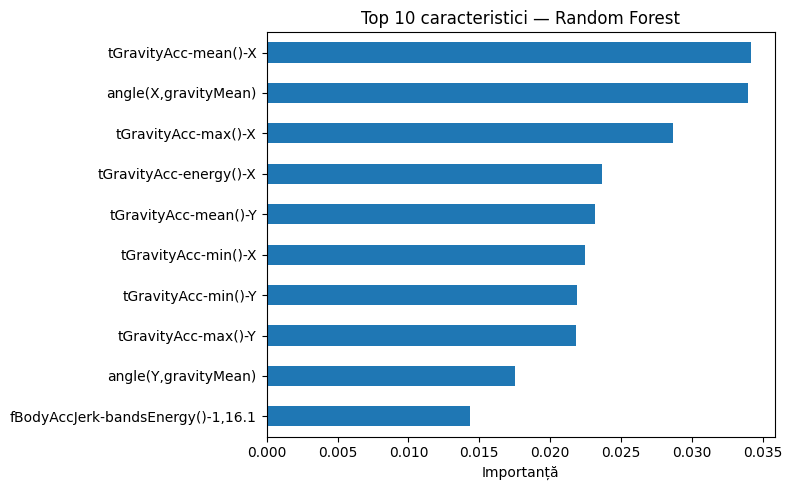

Acuratețe Random Forest: 0.9816
Acuratețe AdaBoost:      0.3510
Acuratețe Bagging:       0.9670
Concluzie: dintre AdaBoost și Bagging, performanța mai bună aparține Bagging.


In [10]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, BaggingClassifier

# Punctul 8.1 — antrenăm Random Forest și calculăm importanța caracteristicilor.
random_forest = RandomForestClassifier(
    n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1
)
random_forest.fit(X_train_cls, y_train_cls)
rf_accuracy = accuracy_score(y_test_cls, random_forest.predict(X_test_cls))
importances = pd.Series(
    random_forest.feature_importances_, index=X_cls.columns
).nlargest(10).sort_values()

plt.figure(figsize=(8, 5))
importances.plot(kind='barh')
plt.xlabel('Importanță')
plt.title('Top 10 caracteristici — Random Forest')
plt.tight_layout()
plt.show()

# Punctul 8.2 — antrenăm și comparăm modelele AdaBoost și Bagging.
ada_model = AdaBoostClassifier(
    n_estimators=50, learning_rate=0.5, random_state=RANDOM_STATE
)
bagging_model = BaggingClassifier(
    n_estimators=30, random_state=RANDOM_STATE, n_jobs=-1
)
ada_model.fit(X_train_cls, y_train_cls)
bagging_model.fit(X_train_cls, y_train_cls)
ada_accuracy = accuracy_score(y_test_cls, ada_model.predict(X_test_cls))
bagging_accuracy = accuracy_score(y_test_cls, bagging_model.predict(X_test_cls))
print(f'Acuratețe Random Forest: {rf_accuracy:.4f}')
print(f'Acuratețe AdaBoost:      {ada_accuracy:.4f}')
print(f'Acuratețe Bagging:       {bagging_accuracy:.4f}')
print(f'Concluzie: dintre AdaBoost și Bagging, performanța mai bună aparține {"Bagging" if bagging_accuracy > ada_accuracy else "AdaBoost"}.')

## 9. Stacking
1. Construiește un model de tip Stacking utilizând Random Forest, SVM și Logistic Regression ca modele de bază.
2. Utilizează un model Logistic Regression ca meta-model.
3. Afișează acuratețea finală pe setul de testare.

In [11]:
from sklearn.ensemble import StackingClassifier
from sklearn.feature_selection import SelectKBest, f_classif

# Pregătim datele pentru Stacking selectând cele mai relevante 50 de caracteristici.
selector = SelectKBest(score_func=f_classif, k=50)
X_train_stack = selector.fit_transform(X_train_cls, y_train_cls)
X_test_stack = selector.transform(X_test_cls)

# Punctul 9.1 — definim Random Forest, SVM și Logistic Regression ca modele de bază.
base_models = [
    ('rf', RandomForestClassifier(n_estimators=50, random_state=RANDOM_STATE, n_jobs=-1)),
    ('svm', make_pipeline(StandardScaler(), SVC(kernel='linear', random_state=RANDOM_STATE))),
    ('lr', make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)))
]
# Punctul 9.2 — folosim Logistic Regression ca meta-model al ansamblului.
stacking_model = StackingClassifier(
    estimators=base_models,
    final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    cv=3,
    n_jobs=-1
)
# Punctul 9.3 — antrenăm modelul Stacking și afișăm acuratețea pe setul de testare.
stacking_model.fit(X_train_stack, y_train_cls)
stacking_accuracy = accuracy_score(y_test_cls, stacking_model.predict(X_test_stack))
print(f'Acuratețe finală Stacking: {stacking_accuracy:.4f}')
print('Concluzie: meta-modelul combină predicțiile celor trei clasificatori de bază.')

Acuratețe finală Stacking: 0.9218
Concluzie: meta-modelul combină predicțiile celor trei clasificatori de bază.
